# Online Retail – Phân tích dữ liệu (Phase 1–3)

Câu hỏi: lịch sử mua hàng **trước 01/06/2011** có dự đoán được chi tiêu trong **01/06–31/08/2011** của những khách đã xuất hiện trong lịch sử không?

Notebook này gồm Phase 1–3: hiểu dữ liệu, tiền xử lý, tạo bảng khách hàng và EDA trên tập train. Kết quả được lưu cạnh file dữ liệu để notebook predict (Phase 4–7) dùng tiếp.

Notebook chạy được theo hai cách đặt file: cấu trúc repo (notebook trong `analysis/`, dữ liệu trong `../dataset/`) hoặc đặt notebook chung một thư mục với file Excel, như khi nộp từng file.

## Thiết lập

In [1]:
import hashlib
import json
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
from scipy import stats
from sklearn.model_selection import train_test_split

sns.set_theme(style='whitegrid', font='DejaVu Sans', font_scale=1.05)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:,.4f}'.format)

In [2]:
# Tìm dữ liệu ở thư mục hiện tại (nộp từng file) hoặc ../dataset (cấu trúc repo);
# tiền tố nhóm (NhomXX) lấy theo tên file nên đổi tên nhóm không phải sửa code
SEARCH_DIRS = [Path('.'), Path('../dataset')]
DATA_FILES = sorted(p for d in SEARCH_DIRS for p in d.glob('Nhom*_Online_Retail.xlsx'))
if len(DATA_FILES) != 1:
    raise FileNotFoundError(f'Cần đúng một file Nhom*_Online_Retail.xlsx trong {[str(d) for d in SEARCH_DIRS]}, '
                            f'tìm thấy {len(DATA_FILES)}.')
DATA_PATH = DATA_FILES[0]
DATA_DIR = DATA_PATH.parent
GROUP_PREFIX = DATA_PATH.stem.removesuffix('_Online_Retail')
MODEL_DATA_PATH = DATA_DIR / f'{GROUP_PREFIX}_Du_lieu_mo_hinh.csv'
OUT_DIR = DATA_DIR / f'{GROUP_PREFIX}_Ket_qua'   # kết quả luôn nằm cạnh file dữ liệu
FIG_DIR = OUT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_COLUMNS = ['InvoiceNo', 'StockCode', 'Description', 'Quantity',
                    'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
EXPECTED_SHAPE = (541909, 8)
EXPECTED_SHA256 = '43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d'
ITEM_CODE_PATTERN = r'\d{5}[A-Z]*'   # mã hàng hóa: 5 chữ số, có thể kèm hậu tố chữ cái

HISTORY_START = pd.Timestamp('2010-12-01')
CUTOFF = pd.Timestamp('2011-06-01')       # X tính trước mốc này
LABEL_END = pd.Timestamp('2011-09-01')    # y tính từ CUTOFF đến trước mốc này
RECENCY_BINS = [0, 30, 90, np.inf]
RECENCY_LABELS = ['≤30 ngày', '31–90 ngày', '>90 ngày']

TARGET = 'FutureSpend'
FEATURES = ['Monetary', 'Frequency', 'Recency', 'Tenure', 'Products', 'IsUK']
RANDOM_STATE = 42
TEST_SIZE = 0.30

MAIN_COLOR = '#146482'
ACCENT_COLOR = '#b45538'
LIGHT_COLOR = '#b6d5df'

In [3]:
def pct(x, d=2):
    return f'{x * 100:.{d}f}%'

def save_fig(fig, name):
    """Lưu hình vào thư mục figures để báo cáo và slide dùng lại."""
    fig.tight_layout()
    fig.savefig(FIG_DIR / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()

VERSIONS = {'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'scipy': scipy.__version__,
            'scikit-learn': sklearn.__version__, 'seaborn': sns.__version__}
print('Phiên bản thư viện:', VERSIONS)

Phiên bản thư viện: {'python': '3.12.3', 'numpy': '2.3.5', 'pandas': '2.2.3', 'scipy': '1.17.0', 'scikit-learn': '1.8.0', 'seaborn': '0.13.2'}


# Phase 1. Thu thập và hiểu dữ liệu
## Step 1. Nạp dữ liệu

Dữ liệu Online Retail do UCI cung cấp (Chen, 2015; DOI 10.24432/C5BW33; giấy phép CC BY 4.0), không tự thu thập. Một dòng là **một dòng hàng trong hóa đơn**, không phải một hóa đơn hay một khách hàng.

In [4]:
df_raw = pd.read_excel(DATA_PATH, engine='openpyxl')
assert df_raw.columns.tolist() == EXPECTED_COLUMNS
assert df_raw.shape == EXPECTED_SHAPE, 'Kiểm tra lại phiên bản dataset.'
raw_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print(f'Số dòng: {df_raw.shape[0]:,} | Số cột: {df_raw.shape[1]}')
print('SHA256:', raw_sha256)
df_raw.dtypes.to_frame('dtype').T

Số dòng: 541,909 | Số cột: 8
SHA256: 43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
dtype,object,object,object,int64,datetime64[ns],float64,float64,object


In [5]:
df_raw.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.5500,"17,850.0000",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.3900,"17,850.0000",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.7500,"17,850.0000",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.3900,"17,850.0000",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.3900,"17,850.0000",United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.6500,"17,850.0000",United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.2500,"17,850.0000",United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.8500,"17,850.0000",United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.8500,"17,850.0000",United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.6900,"13,047.0000",United Kingdom


In [6]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


## Step 2. Khám phá cấu trúc dữ liệu

`InvoiceNo`, `StockCode` và `CustomerID` là **mã định danh** dù Excel lưu một phần dưới dạng số; không tính toán số học trên các cột này.

In [7]:
# (nhóm, ý nghĩa, loại biến)
VAR_INFO = {
    'InvoiceNo':   ('Hóa đơn', 'Mã hóa đơn; bắt đầu bằng C là hóa đơn hủy', 'Định danh'),
    'StockCode':   ('Sản phẩm', 'Mã hàng', 'Định danh'),
    'Description': ('Sản phẩm', 'Tên hàng', 'Văn bản'),
    'Quantity':    ('Dòng hàng', 'Số lượng trên dòng hàng', 'Số'),
    'InvoiceDate': ('Hóa đơn', 'Ngày giờ lập hóa đơn', 'Thời gian'),
    'UnitPrice':   ('Dòng hàng', 'Đơn giá (GBP)', 'Số'),
    'CustomerID':  ('Khách hàng', 'Mã khách hàng', 'Định danh'),
    'Country':     ('Khách hàng', 'Quốc gia của khách', 'Phân loại'),
}

var_table = pd.DataFrame({
    'group': [VAR_INFO[c][0] for c in df_raw.columns],
    'meaning': [VAR_INFO[c][1] for c in df_raw.columns],
    'kind': [VAR_INFO[c][2] for c in df_raw.columns],
    'dtype': df_raw.dtypes.astype(str).values,
    'n_unique': df_raw.nunique().values,
    'examples': [', '.join(map(str, df_raw[c].dropna().unique()[:3])) for c in df_raw.columns],
}, index=df_raw.columns)
var_table

,group,meaning,kind,dtype,n_unique,examples
InvoiceNo,Hóa đơn,Mã hóa đơn; bắt đầu bằng C là hóa đơn hủy,Định danh,object,25900,"536365, 536366, 536367"
StockCode,Sản phẩm,Mã hàng,Định danh,object,4070,"85123A, 71053, 84406B"
Description,Sản phẩm,Tên hàng,Văn bản,object,4223,"WHITE HANGING HEART T-LIGHT HOLDER, WHITE META..."
Quantity,Dòng hàng,Số lượng trên dòng hàng,Số,int64,722,"6, 8, 2"
InvoiceDate,Hóa đơn,Ngày giờ lập hóa đơn,Thời gian,datetime64[ns],23260,"2010-12-01 08:26:00, 2010-12-01 08:28:00, 2010..."
UnitPrice,Dòng hàng,Đơn giá (GBP),Số,float64,1630,"2.55, 3.39, 2.75"
CustomerID,Khách hàng,Mã khách hàng,Định danh,float64,4372,"17850.0, 13047.0, 12583.0"
Country,Khách hàng,Quốc gia của khách,Phân loại,object,38,"United Kingdom, France, Australia"


In [8]:
NUM_COLS = ['Quantity', 'UnitPrice']

num_desc = df_raw[NUM_COLS].describe().T
num_desc['skew'] = df_raw[NUM_COLS].skew()
num_desc['%zero'] = (df_raw[NUM_COLS] == 0).mean() * 100
num_desc['%negative'] = (df_raw[NUM_COLS] < 0).mean() * 100
num_desc

,count,mean,std,min,25%,50%,75%,max,skew,%zero,%negative
Quantity,"541,909.0000",9.5522,218.0812,"-80,995.0000",1.0000,3.0000,10.0000,"80,995.0000",-0.2641,0.0000,1.9605
UnitPrice,"541,909.0000",4.6111,96.7599,"-11,062.0600",1.2500,2.0800,4.1300,"38,970.0000",186.5070,0.4641,0.0004


In [9]:
TEXT_COLS = ['InvoiceNo', 'StockCode', 'Description', 'Country']
df_raw[TEXT_COLS].astype('string').describe().T

,count,unique,top,freq
InvoiceNo,541909,25900,573585,1114
StockCode,541909,4070,85123A,2313
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369
Country,541909,38,United Kingdom,495478


In [10]:
# Phân bố dòng hàng theo quốc gia (10 quốc gia nhiều dòng nhất)
country_dist = pd.DataFrame({'count': df_raw['Country'].value_counts(),
                             '%': df_raw['Country'].value_counts(normalize=True) * 100})
country_dist.head(10)

,count,%
Country,,
United Kingdom,495478,91.4320
Germany,9495,1.7521
France,8557,1.5790
EIRE,8196,1.5124
Spain,2533,0.4674
Netherlands,2371,0.4375
Belgium,2069,0.3818
Switzerland,2002,0.3694
Portugal,1519,0.2803


In [11]:
# Tổng quan bộ dữ liệu
raw_invoice = df_raw['InvoiceNo'].astype('string').str.strip().str.upper()
raw_code = df_raw['StockCode'].astype('string').str.strip().str.upper()
is_cancelled = raw_invoice.str.startswith('C', na=False)
is_item_code = raw_code.str.fullmatch(ITEM_CODE_PATTERN, na=False)

overview = pd.Series({
    'Số dòng': f'{len(df_raw):,}',
    'Số cột': df_raw.shape[1],
    'Từ ngày': df_raw['InvoiceDate'].min(),
    'Đến ngày': df_raw['InvoiceDate'].max(),
    'Số hóa đơn': f"{df_raw['InvoiceNo'].nunique():,}",
    'Số mã hàng': f"{df_raw['StockCode'].nunique():,}",
    'Số mã khách': f"{df_raw['CustomerID'].nunique():,}",
    'Số quốc gia': df_raw['Country'].nunique(),
    'Ô khuyết (NaN)': f'{int(df_raw.isna().sum().sum()):,}',
    'Dòng trùng toàn bộ': f'{int(df_raw.duplicated().sum()):,}',
    'Bộ nhớ (MB)': round(df_raw.memory_usage(deep=True).sum() / 1024**2, 2),
    'SHA256 khớp bản gốc': raw_sha256 == EXPECTED_SHA256,
}, name='value').to_frame()
overview

,value
Số dòng,"541,909"
Số cột,8
Từ ngày,2010-12-01 08:26:00
Đến ngày,2011-12-09 12:50:00
Số hóa đơn,"25,900"
Số mã hàng,"4,070"
Số mã khách,"4,372"
Số quốc gia,38
Ô khuyết (NaN),"136,534"
Dòng trùng toàn bộ,"5,268"


In [12]:
# Các vấn đề cần xử lý (phát hiện tự động trên file thực tế)
issues = pd.DataFrame([
    ('Thiếu CustomerID', f"{pct(df_raw['CustomerID'].isna().mean(), 3)} số dòng"),
    ('Thiếu Description', f"{df_raw['Description'].isna().sum():,} dòng"),
    ('Dòng trùng toàn bộ', f'{df_raw.duplicated().sum():,} dòng'),
    ('Hóa đơn hủy (InvoiceNo bắt đầu bằng C)', f'{is_cancelled.sum():,} dòng'),
    ('Quantity ≤ 0', f"{(df_raw['Quantity'] <= 0).sum():,} dòng"),
    ('UnitPrice ≤ 0', f"{(df_raw['UnitPrice'] <= 0).sum():,} dòng"),
    ('Mã không phải hàng hóa (POST, M, DOT, ...)', f'{(~is_item_code).sum():,} dòng'),
    ('Lệch phải mạnh (|skew| > 2)', ', '.join(num_desc.index[num_desc['skew'].abs() > 2])),
], columns=['issue', 'detail'])
issues

,issue,detail
0,Thiếu CustomerID,24.927% số dòng
1,Thiếu Description,"1,454 dòng"
2,Dòng trùng toàn bộ,"5,268 dòng"
3,Hóa đơn hủy (InvoiceNo bắt đầu bằng C),"9,288 dòng"
4,Quantity ≤ 0,"10,624 dòng"
5,UnitPrice ≤ 0,"2,517 dòng"
6,"Mã không phải hàng hóa (POST, M, DOT, ...)","2,995 dòng"
7,Lệch phải mạnh (|skew| > 2),UnitPrice


Trang UCI ghi bộ dữ liệu không khuyết, nhưng kiểm kê file thực tế cho thấy có khuyết, trùng và giao dịch hủy. Bài làm lấy kết quả kiểm kê file làm căn cứ.

# Phase 2. Tiền xử lý dữ liệu
## Step 3. Kiểm tra và làm sạch dữ liệu

In [13]:
missing = df_raw.isna().sum().to_frame('missing_rows')
missing['missing_pct'] = 100 * missing['missing_rows'] / len(df_raw)
missing.to_csv(OUT_DIR / 'raw_missing.csv', encoding='utf-8-sig')
missing

,missing_rows,missing_pct
InvoiceNo,0,0.0000
StockCode,0,0.0000
Description,1454,0.2683
Quantity,0,0.0000
InvoiceDate,0,0.0000
UnitPrice,0,0.0000
CustomerID,135080,24.9267
Country,0,0.0000


In [14]:
# Mỗi quyết định gắn với một lý do nghiệp vụ
decisions = pd.DataFrame([
    ('Dòng trùng toàn bộ 8 cột', 'Loại',
     'Không có khóa dòng duy nhất nên đây là giả định làm sạch; kiểm tra độ nhạy bằng phương án giữ trùng'),
    ('Hóa đơn hủy (C...)', 'Loại', 'Phạm vi là chi tiêu mua hàng dương, không phải doanh thu thuần'),
    ('Quantity ≤ 0 hoặc UnitPrice ≤ 0', 'Loại', 'Hoàn trả, điều chỉnh hoặc hàng không tính tiền nằm ngoài phạm vi'),
    ('Thiếu CustomerID', 'Loại, không điền',
     'Là mã định danh; điền mean/mode sẽ gán giao dịch cho người khác'),
    ('Mã ngoài hàng hóa (POST, M, C2, ...)', 'Loại', 'Phí vận chuyển, dịch vụ hoặc điều chỉnh, không phải hàng hóa'),
    ('Thiếu Description', 'Giữ', 'Description không tham gia mô hình; không loại giao dịch hợp lệ vì thiếu mô tả'),
    ('Ngoại lệ lớn (khách mua sỉ)', 'Giữ', 'Có thể là giao dịch thật; giữ để đánh giá cả khách khó dự đoán'),
    ('Định dạng mã định danh', 'Chuyển sang chuỗi', 'Bỏ khoảng trắng, StockCode viết hoa; CustomerID bỏ phần .0'),
], columns=['issue', 'decision', 'reason'])
decisions

,issue,decision,reason
0,Dòng trùng toàn bộ 8 cột,Loại,Không có khóa dòng duy nhất nên đây là giả địn...
1,Hóa đơn hủy (C...),Loại,"Phạm vi là chi tiêu mua hàng dương, không phải..."
2,Quantity ≤ 0 hoặc UnitPrice ≤ 0,Loại,"Hoàn trả, điều chỉnh hoặc hàng không tính tiền..."
3,Thiếu CustomerID,"Loại, không điền",Là mã định danh; điền mean/mode sẽ gán giao dị...
4,"Mã ngoài hàng hóa (POST, M, C2, ...)",Loại,"Phí vận chuyển, dịch vụ hoặc điều chỉnh, không..."
5,Thiếu Description,Giữ,Description không tham gia mô hình; không loại...
6,Ngoại lệ lớn (khách mua sỉ),Giữ,Có thể là giao dịch thật; giữ để đánh giá cả k...
7,Định dạng mã định danh,Chuyển sang chuỗi,"Bỏ khoảng trắng, StockCode viết hoa; CustomerI..."


In [15]:
def keep_rows(frame, mask, step, audit_rows):
    """Giữ các dòng thỏa mask và ghi số dòng trước/sau; số dòng loại không đếm chồng."""
    kept = frame.loc[mask].copy()
    audit_rows.append({'step': step, 'before': len(frame),
                       'removed': len(frame) - len(kept), 'after': len(kept)})
    return kept

def clean_sales(data, drop_duplicates=True):
    """Lọc tuần tự theo bảng quyết định; trả về dữ liệu sạch, nhật ký lọc và các mã bị loại."""
    audit_rows = []
    sales = data.copy()
    if drop_duplicates:
        sales = keep_rows(sales, ~sales.duplicated(), '1 Loại dòng trùng toàn bộ', audit_rows)
    sales['InvoiceNo'] = sales['InvoiceNo'].astype('string').str.strip()
    sales['StockCode'] = sales['StockCode'].astype('string').str.strip().str.upper()
    sales['Country'] = sales['Country'].astype('string').str.strip()
    sales['InvoiceDate'] = pd.to_datetime(sales['InvoiceDate'], errors='coerce')

    is_cancelled = sales['InvoiceNo'].str.upper().str.startswith('C', na=False)
    sales = keep_rows(sales, ~is_cancelled, '2 Loại hóa đơn C', audit_rows)
    sales = keep_rows(sales, sales['Quantity'] > 0, '3 Giữ Quantity dương', audit_rows)
    sales = keep_rows(sales, sales['UnitPrice'] > 0, '4 Giữ UnitPrice dương', audit_rows)
    sales = keep_rows(sales, sales['CustomerID'].notna(), '5 Có CustomerID', audit_rows)
    is_item = sales['StockCode'].str.fullmatch(ITEM_CODE_PATTERN, na=False)
    excluded_codes = sales.loc[~is_item, 'StockCode'].value_counts()
    sales = keep_rows(sales, is_item, '6 Chỉ mã hàng hóa', audit_rows)
    has_date_country = sales['InvoiceDate'].notna() & sales['Country'].notna()
    sales = keep_rows(sales, has_date_country, '7 Có ngày và quốc gia', audit_rows)

    sales['CustomerID'] = sales['CustomerID'].astype('int64').astype('string')
    sales['LineSpend'] = sales['Quantity'] * sales['UnitPrice']
    return sales, pd.DataFrame(audit_rows), excluded_codes

In [16]:
df, audit, excluded_codes = clean_sales(df_raw)
assert (df['LineSpend'] > 0).all()
assert audit['removed'].sum() + len(df) == len(df_raw)
audit.to_csv(OUT_DIR / 'cleaning_audit.csv', index=False, encoding='utf-8-sig')
print(f"Sau làm sạch: {df.shape[0]:,} dòng | {df['CustomerID'].nunique():,} khách")
audit

Sau làm sạch: 391,150 dòng | 4,334 khách


,step,before,removed,after
0,1 Loại dòng trùng toàn bộ,541909,5268,536641
1,2 Loại hóa đơn C,536641,9251,527390
2,3 Giữ Quantity dương,527390,1336,526054
3,4 Giữ UnitPrice dương,526054,1176,524878
4,5 Có CustomerID,524878,132186,392692
5,6 Chỉ mã hàng hóa,392692,1542,391150
6,7 Có ngày và quốc gia,391150,0,391150


In [17]:
# Mã bị loại ở bước 6 (đếm trên phần dữ liệu còn lại sau bước 5)
excluded_codes.to_frame('rows')

,rows
StockCode,
POST,1099
M,279
C2,133
DOT,16
BANK CHARGES,12
PADS,3


## Step 4. Tạo bảng khách hàng dùng cho dự đoán

- Mỗi khách mua trước `CUTOFF` là một mẫu; X tính **hoàn toàn trước** `CUTOFF`.
- y = tổng `LineSpend` từ `CUTOFF` (bao gồm) đến `LABEL_END` (không bao gồm). Khách không mua trong cửa sổ y nhận **0** và vẫn được giữ.
- `Country` lấy mode trong lịch sử; nếu hòa, chọn theo thứ tự chữ cái. Khách xuất hiện lần đầu sau `CUTOFF` nằm ngoài phạm vi.
- Không đưa Quantity/UnitPrice của kỳ mục tiêu vào X, vì như vậy mô hình chỉ học lại công thức tính chi tiêu (rò rỉ mục tiêu).

In [18]:
def build_customers(sales):
    """Gom lịch sử theo khách để tạo X và cộng chi tiêu trong cửa sổ mục tiêu để tạo y."""
    history = sales.loc[(sales['InvoiceDate'] >= HISTORY_START) & (sales['InvoiceDate'] < CUTOFF)].copy()
    future = sales.loc[(sales['InvoiceDate'] >= CUTOFF) & (sales['InvoiceDate'] < LABEL_END)].copy()
    customers = history.groupby('CustomerID').agg(
        FirstPurchase=('InvoiceDate', 'min'), LastPurchase=('InvoiceDate', 'max'),
        Frequency=('InvoiceNo', 'nunique'), Monetary=('LineSpend', 'sum'),
        Products=('StockCode', 'nunique'))
    customers['Country'] = history.groupby('CustomerID')['Country'].agg(lambda s: sorted(s.mode())[0])
    customers['Recency'] = (CUTOFF - customers['LastPurchase']).dt.total_seconds() / 86400
    customers['Tenure'] = (CUTOFF - customers['FirstPurchase']).dt.total_seconds() / 86400
    future_spend = future.groupby('CustomerID')['LineSpend'].sum()
    customers[TARGET] = future_spend.reindex(customers.index, fill_value=0)
    customers['RecencyGroup'] = pd.cut(customers['Recency'], bins=RECENCY_BINS,
                                       labels=RECENCY_LABELS, include_lowest=True)
    country_group = customers['Country'].eq('United Kingdom').map({True: 'UK', False: 'Other'})
    country_dummies = pd.get_dummies(country_group, prefix='Country', dtype=int)
    customers['IsUK'] = country_dummies['Country_UK']
    return history, future, customers

In [19]:
history, future, customers = build_customers(df)
assert history['InvoiceDate'].max() < future['InvoiceDate'].min()
assert customers.index.is_unique and customers[TARGET].notna().all()
assert len(customers) == history['CustomerID'].nunique()
future_known = future.loc[future['CustomerID'].isin(customers.index)]
assert np.isclose(customers[TARGET].sum(), future_known['LineSpend'].sum())

new_future_customers = future.loc[~future['CustomerID'].isin(customers.index), 'CustomerID'].nunique()
print(f'Khách lịch sử: {len(customers):,} | dòng lịch sử: {len(history):,} | dòng cửa sổ y: {len(future):,}')
print(f'Khách mới trong cửa sổ y (ngoài phạm vi): {new_future_customers}')
customers.head()

Khách lịch sử: 2,716 | dòng lịch sử: 143,150 | dòng cửa sổ y: 79,977
Khách mới trong cửa sổ y (ngoài phạm vi): 598


,FirstPurchase,LastPurchase,Frequency,Monetary,Products,Country,Recency,Tenure,FutureSpend,RecencyGroup,IsUK
CustomerID,,,,,,,,,,,
12346,2011-01-18 10:01:00,2011-01-18 10:01:00,1,"77,183.6000",1,United Kingdom,133.5826,133.5826,0.0000,>90 ngày,1
12347,2010-12-07 14:57:00,2011-04-07 10:43:00,3,"1,823.4300",63,Iceland,54.5535,175.3771,967.4300,31–90 ngày,0
12348,2010-12-16 19:09:00,2011-04-05 10:47:00,3,"1,167.2400",21,Finland,56.5507,166.2021,0.0000,31–90 ngày,0
12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,294.4000,16,Norway,118.3326,118.3326,0.0000,>90 ngày,0
12352,2011-02-16 12:33:00,2011-03-22 16:08:00,4,641.5100,24,Norway,70.3278,104.4771,0.0000,31–90 ngày,0


In [20]:
# Định nghĩa đặc trưng được cố định trước EDA; CustomerID chỉ là khóa, không phải biến đầu vào
FEATURE_INFO = {
    'Monetary':  ('Tổng chi tiêu lịch sử', 'GBP'),
    'Frequency': ('Số hóa đơn khác nhau', 'hóa đơn'),
    'Recency':   ('Số ngày từ lần mua cuối đến CUTOFF (có phần lẻ)', 'ngày'),
    'Tenure':    ('Số ngày từ lần mua đầu đến CUTOFF (có phần lẻ)', 'ngày'),
    'Products':  ('Số mã hàng khác nhau', 'mã hàng'),
    'IsUK':      ('Quốc gia phổ biến trong lịch sử là United Kingdom', '0/1'),
    TARGET:      ('Chi tiêu từ 01/06 đến trước 01/09/2011', 'GBP'),
}
assert TARGET not in FEATURES and 'CustomerID' not in FEATURES

feature_table = pd.DataFrame(FEATURE_INFO, index=['definition', 'unit']).T
feature_table['role'] = np.where(feature_table.index == TARGET, 'Mục tiêu (y)', 'Đầu vào (X)')
feature_table

,definition,unit,role
Monetary,Tổng chi tiêu lịch sử,GBP,Đầu vào (X)
Frequency,Số hóa đơn khác nhau,hóa đơn,Đầu vào (X)
Recency,Số ngày từ lần mua cuối đến CUTOFF (có phần lẻ),ngày,Đầu vào (X)
Tenure,Số ngày từ lần mua đầu đến CUTOFF (có phần lẻ),ngày,Đầu vào (X)
Products,Số mã hàng khác nhau,mã hàng,Đầu vào (X)
IsUK,Quốc gia phổ biến trong lịch sử là United Kingdom,0/1,Đầu vào (X)
FutureSpend,Chi tiêu từ 01/06 đến trước 01/09/2011,GBP,Mục tiêu (y)


In [21]:
# Chia 70/30 theo mã khách (notebook predict tái tạo đúng phép chia này)
X = customers[FEATURES]
y = customers[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
assert set(X_train.index).isdisjoint(X_test.index)
customers['Split'] = np.where(customers.index.isin(X_train.index), 'train', 'test')

split_info = pd.DataFrame({
    'rows': [len(X_train), len(X_test)],
    'share': [len(X_train) / len(X), len(X_test) / len(X)],
    'y = 0 rate': [y_train.eq(0).mean(), y_test.eq(0).mean()],
}, index=['train', 'test'])
print(f'Không mua trong cửa sổ y: {int(y.eq(0).sum()):,} khách ({pct(y.eq(0).mean())})')
split_info

Không mua trong cửa sổ y: 1,370 khách (50.44%)


,rows,share,y = 0 rate
train,1901,0.6999,0.5097
test,815,0.3001,0.4920


In [22]:
customers.reset_index().to_csv(MODEL_DATA_PATH, index=False, encoding='utf-8-sig')
print('Đã lưu dữ liệu mô hình:', MODEL_DATA_PATH)

Đã lưu dữ liệu mô hình: ../dataset/NhomXX_Du_lieu_mo_hinh.csv


In [23]:
# Phương án giữ dòng trùng, dùng cho kiểm tra độ nhạy ở Phase 7 (cùng mã khách và cùng phép chia)
df_keep_dup, _, _ = clean_sales(df_raw, drop_duplicates=False)
_, _, customers_keep_dup = build_customers(df_keep_dup)
assert set(customers_keep_dup.index) == set(customers.index)
customers_keep_dup.reset_index().to_csv(OUT_DIR / 'customers_keep_duplicates.csv',
                                        index=False, encoding='utf-8-sig')

dedup_effect = pd.DataFrame({
    'drop_duplicates': [len(df), customers['Monetary'].sum(), customers[TARGET].sum()],
    'keep_duplicates': [len(df_keep_dup), customers_keep_dup['Monetary'].sum(), customers_keep_dup[TARGET].sum()],
}, index=['clean_rows', 'Monetary_total_GBP', 'FutureSpend_total_GBP'])
dedup_effect

,drop_duplicates,keep_duplicates
clean_rows,"391,150.0000","396,337.0000"
Monetary_total_GBP,"3,267,003.2800","3,275,175.0400"
FutureSpend_total_GBP,"1,556,994.1200","1,559,833.5800"


# Phase 3. Khám phá dữ liệu (EDA) – tập train
## Step 5. Phân tích phân phối

Phân tích liên quan đến y **chỉ dùng tập train**. Không dùng y_test để tìm biến, chọn mô hình hay điều chỉnh tham số. Biểu đồ theo tháng và theo quốc gia mô tả dữ liệu lịch sử (phần X), không chứa y.

In [24]:
train_df = customers.loc[X_train.index].copy()

In [25]:
descriptive = train_df[FEATURES[:-1] + [TARGET]].describe().T
for c in ['Monetary', TARGET]:
    descriptive.loc[c, 'mode_first'] = train_df[c].mode().iloc[0]
descriptive['range'] = descriptive['max'] - descriptive['min']
descriptive['IQR'] = descriptive['75%'] - descriptive['25%']
descriptive['variance'] = train_df[descriptive.index].var()    # phương sai mẫu, ddof=1
descriptive['CV_pct'] = descriptive['std'] / descriptive['mean'] * 100
descriptive['skew'] = train_df[descriptive.index].skew()
descriptive['excess_kurtosis'] = train_df[descriptive.index].kurt()
descriptive.to_csv(OUT_DIR / 'descriptive_train.csv', encoding='utf-8-sig')
descriptive

,count,mean,std,min,25%,50%,75%,max,mode_first,range,IQR,variance,CV_pct,skew,excess_kurtosis
Monetary,"1,901.0000","1,203.3832","4,465.2752",2.9000,236.0200,455.1800,"1,028.5600","110,155.1200",45.0000,"110,152.2200",792.5400,"19,938,682.7705",371.0601,14.9135,280.1395
Frequency,"1,901.0000",2.6528,3.6766,1.0000,1.0000,2.0000,3.0000,59.0000,NaN,58.0000,2.0000,13.5173,138.5920,6.9483,73.8798
Recency,"1,901.0000",63.8265,52.9231,0.3465,19.4965,49.4514,97.5944,181.5882,NaN,181.2417,78.0979,"2,800.8540",82.9171,0.8004,-0.4853
Tenure,"1,901.0000",111.8435,54.8337,0.3528,67.6368,118.3889,168.5514,181.6431,NaN,181.2903,100.9146,"3,006.7361",49.0272,-0.3063,-1.1663
Products,"1,901.0000",40.2188,50.1879,1.0000,12.0000,25.0000,52.0000,879.0000,NaN,878.0000,40.0000,"2,518.8237",124.7870,5.4652,59.8753
FutureSpend,"1,901.0000",533.3173,"2,819.6560",0.0000,0.0000,0.0000,435.7800,"65,895.1200",0.0000,"65,895.1200",435.7800,"7,950,459.7568",528.7014,17.6072,362.5787


In [26]:
# Ngoại lệ theo IQR của y: chỉ đếm, không loại (có thể là khách mua sỉ hợp lệ)
q1, q3 = y_train.quantile([0.25, 0.75])
outlier_threshold = q3 + 1.5 * (q3 - q1)
n_outliers = int(y_train.gt(outlier_threshold).sum())
print(f'Ngưỡng ngoại lệ IQR của y (train): {outlier_threshold:,.2f} GBP | số khách vượt ngưỡng: {n_outliers} (giữ lại)')

Ngưỡng ngoại lệ IQR của y (train): 1,089.45 GBP | số khách vượt ngưỡng: 173 (giữ lại)


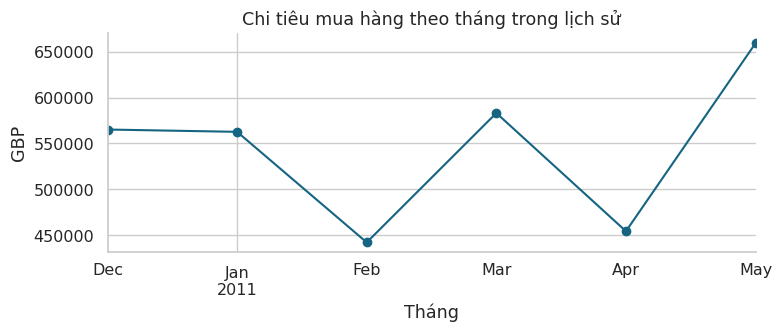

In [27]:
monthly = history.set_index('InvoiceDate')['LineSpend'].resample('MS').sum()
fig, ax = plt.subplots(figsize=(8, 3.5))
monthly.plot(ax=ax, marker='o', color=MAIN_COLOR)
ax.set(title='Chi tiêu mua hàng theo tháng trong lịch sử', xlabel='Tháng', ylabel='GBP')
save_fig(fig, '01_monthly')

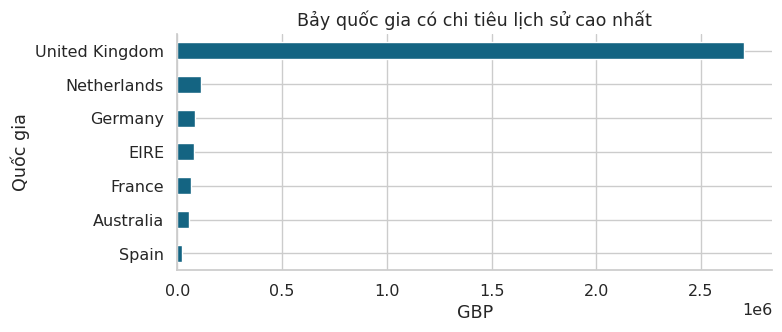

Tổng chi tiêu lịch sử: 3,267,003.28 GBP | United Kingdom: 82.78%


In [28]:
country_totals = history.groupby('Country')['LineSpend'].sum().sort_values(ascending=False)
uk_share = country_totals.loc['United Kingdom'] / country_totals.sum()
fig, ax = plt.subplots(figsize=(8, 3.5))
country_totals.head(7).sort_values().plot.barh(ax=ax, color=MAIN_COLOR)
ax.set(title='Bảy quốc gia có chi tiêu lịch sử cao nhất', xlabel='GBP', ylabel='Quốc gia')
save_fig(fig, '02_country')
print(f"Tổng chi tiêu lịch sử: {history['LineSpend'].sum():,.2f} GBP | United Kingdom: {pct(uk_share)}")

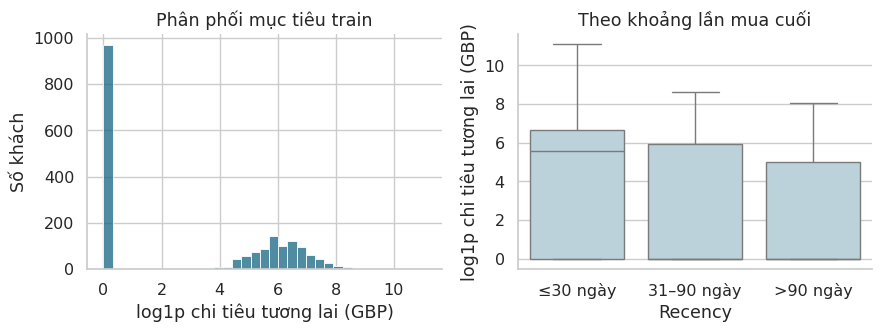

In [29]:
# log1p chỉ đổi trục nhìn; mô hình vẫn dự đoán GBP gốc
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
sns.histplot(np.log1p(y_train), bins=35, ax=axes[0], color=MAIN_COLOR)
axes[0].set(xlabel='log1p chi tiêu tương lai (GBP)', ylabel='Số khách', title='Phân phối mục tiêu train')
sns.boxplot(x=train_df['RecencyGroup'], y=np.log1p(y_train), ax=axes[1], color=LIGHT_COLOR)
axes[1].set(xlabel='Recency', ylabel='log1p chi tiêu tương lai (GBP)', title='Theo khoảng lần mua cuối')
save_fig(fig, '03_distribution')

## Step 6. Quan hệ với mục tiêu

Pearson mô tả liên hệ tuyến tính, không phải quan hệ nhân quả. Sáu đặc trưng đã được định nghĩa trước EDA; EDA giải thích chúng chứ không dùng để chọn biến theo p-value.

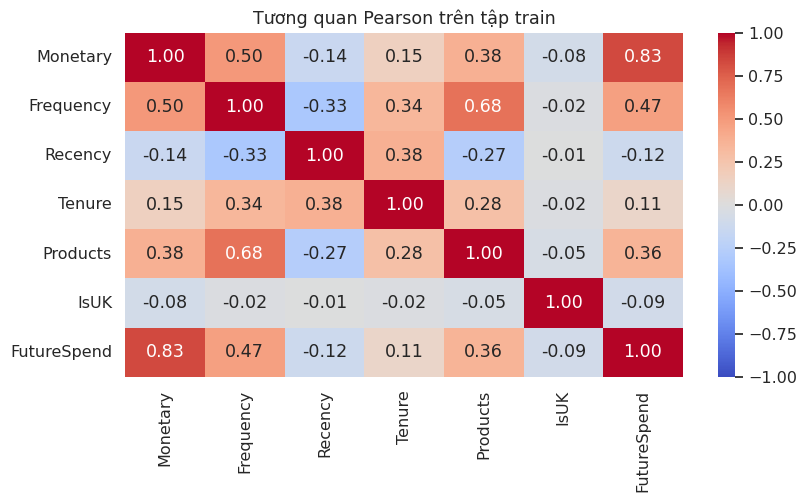

In [30]:
corr = train_df[FEATURES + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(8.5, 5.2))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title('Tương quan Pearson trên tập train')
save_fig(fig, '04_correlation')

In [31]:
pearson_rows = []
for c in FEATURES:
    r, p = stats.pearsonr(train_df[c], y_train)
    pearson_rows.append({'feature': c, 'r': r, 'p_value': p})
pearson = pd.DataFrame(pearson_rows)
pearson.to_csv(OUT_DIR / 'pearson_train.csv', index=False)
# p-value hiển thị dạng khoa học vì nhiều giá trị rất nhỏ; p = 0.00e+00 là nhỏ hơn mức float64 biểu diễn được
pearson.sort_values('r', key=np.abs, ascending=False).assign(p_value=lambda d: d['p_value'].map('{:.2e}'.format))

,feature,r,p_value
0,Monetary,0.8306,0.00e+00
1,Frequency,0.4660,4.25e-103
4,Products,0.3582,1.24e-58
2,Recency,-0.1240,5.88e-08
3,Tenure,0.1090,1.91e-06
5,IsUK,-0.0914,6.62e-05


In [32]:
group_table = train_df.groupby('RecencyGroup', observed=True)[TARGET].agg(['count', 'mean', 'median'])
group_table

,count,mean,median
RecencyGroup,,,
≤30 ngày,731,"1,031.2346",266.1000
31–90 ngày,631,283.8345,0.0000
>90 ngày,539,150.1004,0.0000


In [33]:
recency_uk_pivot = train_df.pivot_table(index='RecencyGroup', columns='IsUK', values=TARGET,
                                        aggfunc='median', observed=True)
recency_uk_pivot

IsUK,0,1
RecencyGroup,,
≤30 ngày,437.0100,248.0600
31–90 ngày,0.0000,0.0000
>90 ngày,0.0000,0.0000


In [34]:
# ANOVA một nhân tố theo RecencyGroup + kiểm tra giả định (Levene) và hai phép thay thế (Welch, Kruskal-Wallis)
groups = [part[TARGET].to_numpy() for _, part in train_df.groupby('RecencyGroup', observed=True)]
f_stat, anova_p = stats.f_oneway(*groups)
levene_stat, levene_p = stats.levene(*groups, center='median')
welch_stat, welch_p = stats.f_oneway(*groups, equal_var=False)
kruskal_stat, kruskal_p = stats.kruskal(*groups)

anova = {'F_classic': float(f_stat), 'p_classic': float(anova_p),
         'Levene_stat': float(levene_stat), 'Levene_p': float(levene_p),
         'F_Welch': float(welch_stat), 'p_Welch': float(welch_p),
         'Kruskal_H': float(kruskal_stat), 'Kruskal_p': float(kruskal_p)}
anova_table = pd.DataFrame([
    ('ANOVA cổ điển', f_stat, anova_p, 'Trung bình các nhóm bằng nhau'),
    ('Levene (median)', levene_stat, levene_p, 'Phương sai các nhóm bằng nhau'),
    ('Welch ANOVA', welch_stat, welch_p, 'Trung bình bằng nhau, không giả định phương sai đều'),
    ('Kruskal-Wallis', kruskal_stat, kruskal_p, 'Phân phối các nhóm như nhau'),
], columns=['test', 'statistic', 'p_value', 'H0']).set_index('test')
anova_table.assign(p_value=anova_table['p_value'].map('{:.2e}'.format))

,statistic,p_value,H0
test,,,
ANOVA cổ điển,19.2066,5.52e-09,Trung bình các nhóm bằng nhau
Levene (median),17.4832,2.99e-08,Phương sai các nhóm bằng nhau
Welch ANOVA,24.5384,3.62e-11,"Trung bình bằng nhau, không giả định phương sa..."
Kruskal-Wallis,188.5765,1.12e-41,Phân phối các nhóm như nhau


Levene bác bỏ phương sai bằng nhau và y lệch phải mạnh, nên không chỉ dựa vào ANOVA cổ điển; Welch và Kruskal-Wallis là phần kiểm tra bổ sung. p nhỏ không có nghĩa hiệu ứng lớn hay có quan hệ nhân quả.

## Lưu kết quả cho notebook predict

In [35]:
analysis_summary = {
    'source_url': 'https://archive.ics.uci.edu/dataset/352/online+retail',
    'doi': '10.24432/C5BW33', 'license': 'CC BY 4.0', 'sha256': raw_sha256,
    'versions': VERSIONS, 'random_state': RANDOM_STATE, 'raw_shape': list(df_raw.shape),
    'missing': df_raw.isna().sum().to_dict(), 'duplicates': int(df_raw.duplicated().sum()),
    'clean_rows': len(df), 'clean_customers': int(df['CustomerID'].nunique()),
    'history_rows': len(history), 'future_rows': len(future),
    'customer_samples': len(customers), 'train_samples': len(X_train), 'test_samples': len(X_test),
    'zero_target_samples': int(y.eq(0).sum()), 'zero_target_pct': float(y.eq(0).mean() * 100),
    'history_spend_GBP': float(history['LineSpend'].sum()),
    'uk_history_share_pct': float(uk_share * 100),
    'new_future_customers': int(new_future_customers),
    'anova_train': anova, 'outlier_threshold_train': float(outlier_threshold),
    'train_outlier_count': n_outliers,
}
(OUT_DIR / 'analysis_summary.json').write_text(
    json.dumps(analysis_summary, ensure_ascii=False, indent=2), encoding='utf-8')
print('Đã lưu kết quả tại:', OUT_DIR)

Đã lưu kết quả tại: ../dataset/NhomXX_Ket_qua
